<a href="https://colab.research.google.com/github/dhruvbit/Machine-project/blob/main/ai_pneumonia_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:
!pip install lightning
!pip install pytorch-lightning

In [61]:
# Measuring Performance
# In the upcoming experiments, you will measure the total time it takes to load the entire dataset for one full epoch using the measure_average_epoch_time helper function.
# This metric is the primary indicator of DataLoader performance in this lab. By minimizing the total epoch time, you can improve the overall efficiency of the training process.

In [62]:
import gc
import os
import json
import matplotlib.pyplot as plt
import torch
import lightning.pytorch as pl
from torch.utils.data import DataLoader
import numpy as np
import torchvision
from torchvision import datasets
from lightning.pytorch.callbacks import EarlyStopping
import time
import gc
import matplotlib.gridspec as gridspec
import torchvision.transforms as transforms
from tqdm.auto import tqdm
from torchvision import models as tv_models

In [63]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"using device: {device}")

using device: cpu


In [64]:
import sys
import warnings

class Blackhole:
    def write(self,message):
      pass
    def flush(self):
      pass

sys.stderr = Blackhole()

warnings.filterwarnings("ignore", category = UserWarning)

In [65]:
torch.set_float32_matmul_precision('medium')

In [66]:
import kagglehub

# Download latest version
data_path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", data_path)
print(os.listdir(data_path))
data_path = os.path.join(data_path,'chest_xray')
print(os.listdir(data_path))

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia
['chest_xray']
['chest_xray', '__MACOSX', 'val', 'test', 'train']


In [67]:
def display_dataset_count(dataset_path):
  """
  Calculates and displays the number of images for each class and the total
    number of images in the train and validation sets.
  """
  class_width = 25
  total_width = 25

  for split in ['train','val']:
    split_path = os.path.join(dataset_path,split)

    if not os.path.join(split_path):
      print(f"\n dsirectory not found{split_path}")

    print(f"--- {split.capitalize()} set ---")

    total_images = 0

    # get the class name from th subdir within the split path and sort them
    class_names = sorted([d for d in os.listdir(split_path) if os.path.isdir(os.path.join(split_path , d))])

    if not class_names:
      print("no class directory")
      continue
    #check if the class directory were found
    for class_name in class_names:
      class_path = os.path.join(split_path , class_name)
      num_images = len(os.listdir(class_path))

      total_images += num_images

      print(f" - {class_name:<{class_width}}: {num_images} images")
      print("—" * (class_width + total_width))
      print(f"  Total: {total_images:>{total_width}} images\n")

In [68]:
display_dataset_count(data_path)

--- Train set ---
 - NORMAL                   : 1341 images
——————————————————————————————————————————————————
  Total:                      1341 images

 - PNEUMONIA                : 3875 images
——————————————————————————————————————————————————
  Total:                      5216 images

--- Val set ---
 - NORMAL                   : 8 images
——————————————————————————————————————————————————
  Total:                         8 images

 - PNEUMONIA                : 8 images
——————————————————————————————————————————————————
  Total:                        16 images



In [69]:
import os
import random

import numpy as np
import seaborn as sns
import torch
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

from torchvision import transforms
from torchmetrics.classification import MulticlassConfusionMatrix
import torch.nn as nn
import torchvision.models as tv_models

In [70]:
def display_random_images(path):
    """
    Displays a grid of random images from the dataset.

    This function shows two random images for each class, ensuring the rows
    always follow the order: NORMAL, BACTERIAL_PNEUMONIA, VIRAL_PNEUMONIA.


    """
    try:
        # Define the exact order for class display
        class_names = ['NORMAL', 'BACTERIAL_PNEUMONIA', 'VIRAL_PNEUMONIA']
        # Get the number of classes
        num_classes = len(class_names)

        # Create a figure with a row for each class and two columns for images
        fig, axs = plt.subplots(num_classes, 2, figsize=(7, 7))

        # Loop through each class in the predefined order
        for i, class_name in enumerate(class_names):
            # Construct the path to the current class directory
            class_path = os.path.join(path, class_name)

            # Check if the class directory actually exists
            if not os.path.isdir(class_path):
                # Print a warning and turn off the axes for the missing directory
                print(f"Warning: Directory for class '{class_name}' not found. Skipping row.")
                # Turn off the axis for the first subplot in the current row
                axs[i, 0].axis('off')
                # Turn off the axis for the second subplot in the current row
                axs[i, 1].axis('off')
                # Continue to the next iteration of the loop
                continue

            # Get a list of all image files in the class directory
            image_files = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

            # Check if there are at least two images in the class directory
            if len(image_files) < 2:
                # Print a warning and turn off the axes if there are not enough images
                print(f"Warning: Class '{class_name}' has fewer than 2 images. Skipping.")
                # Turn off the axis for the first subplot in the current row
                axs[i, 0].axis('off')
                # Turn off the axis for the second subplot in the current row
                axs[i, 1].axis('off')
                # Continue to the next iteration of the loop
                continue

            # Randomly sample two unique image files
            selected_images = random.sample(image_files, 2)

            # Display the two selected images
            for j, image_file in enumerate(selected_images):
                # Construct the full path to the image file
                image_path = os.path.join(class_path, image_file)
                # Open the image using the PIL library
                image = Image.open(image_path)

                # Select the appropriate subplot for the current image
                ax = axs[i, j]
                # Display the image on the subplot with a grayscale colormap
                ax.imshow(image, cmap='gray')
                # Turn off the axis to hide ticks and labels
                ax.axis('off')
                # Set the title of the subplot to the class name
                ax.set_title(class_name, fontsize=12)

        # Adjust the subplot parameters for a tight layout
        plt.tight_layout()
        # Display the figure with the images
        plt.show()

    except FileNotFoundError:
        # Handle the case where the main directory is not found
        print(f"Error: The directory '{path}' was not found.")
    except Exception as e:
        # Handle any other unexpected exceptions
        print(f"An unexpected error occurred: {e}")





























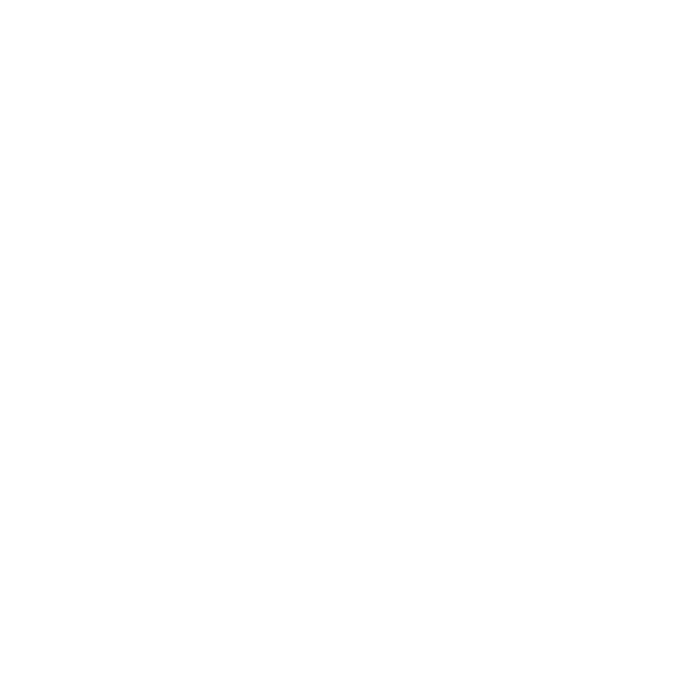

In [71]:
display_random_images(data_path + "train")

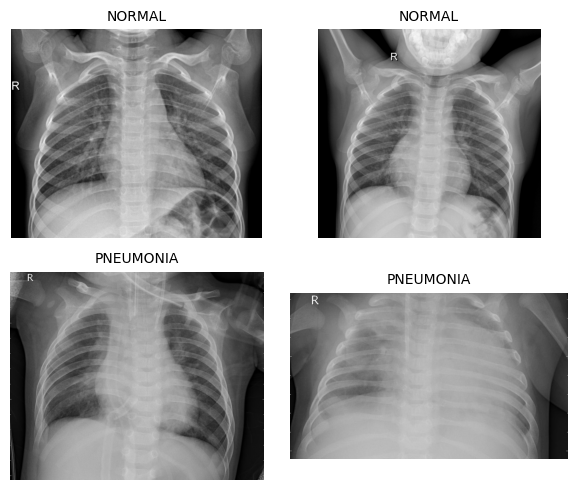

In [72]:
from pathlib import Path
import random
from PIL import Image
import matplotlib.pyplot as plt

def display_samples_easy(data_path, num_per_class=2):
    root = Path(data_path)

    # 1. Grab all image files recursively regardless of nesting
    extensions = ("*.jpeg", "*.jpg", "*.png")
    all_images = []
    for ext in extensions:
        all_images.extend(root.rglob(ext))

    # 2. Group files by their immediate parent folder name (the class)
    class_map = {}
    for img_path in all_images:
        cls = img_path.parent.name
        # Skip macOS metadata or hidden folders
        if cls.startswith(".") or cls == "__MACOSX":
            continue
        class_map.setdefault(cls, []).append(img_path)

    if not class_map:
        print(f"No images found under {data_path}")
        return

    # 3. Plot without hardcoded labels
    classes = sorted(class_map.keys())
    fig, axes = plt.subplots(len(classes), num_per_class, figsize=(3 * num_per_class, 2.5 * len(classes)))

    for row, cls in enumerate(classes):
        samples = random.sample(class_map[cls], min(num_per_class, len(class_map[cls])))
        for col, img_path in enumerate(samples):
            ax = axes[row, col] if len(classes) > 1 else axes[col]
            with Image.open(img_path) as im:
                ax.imshow(im, cmap='gray')
            ax.set_title(cls, fontsize=10)
            ax.axis('off')

    plt.tight_layout()
    plt.show()

# Call it safely on your train directory:
display_samples_easy(os.path.join(data_path, "train"))

In [77]:
TRAIN_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2 , contrast=0.2),
    transforms.RandomAffine(degrees=0,translate=(0.1, 0.1),scale=(0.9,1.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.482, 0.482, 0.482], [0.222, 0.222, 0.222])

])

VAL_TRANSFORM = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),

    transforms.Normalize([0.482, 0.482, 0.482], [0.222, 0.222, 0.222])
])

In [78]:
def create_datasets(train_path,val_path,train_transform,val_transform):
  """
  Create and return the necessary datasets for training and validation.
  """
  train_dataset = datasets.ImageFolder(train_path, train_transform)
  val_dataset = datasets.ImageFolder(val_path,val_transform)

  return train_dataset, val_dataset



In [88]:
def load_dataloader(train_dataset,val_dataset,batch_size,is_trainer_loader):
  """
  create and return either a training of validation datloader
  """
  if is_trainer_loader==True:
    loader = DataLoader(
        train_dataset,
        batch_size = batch_size,
        shuffle = True
    )

  else:
      loader = DataLoader(
          val_dataset,
          batch_size = batch_size,
          shuffle = False
    )

  return loader

In [95]:
class ChestXRayDataModule(pl.LightningDataModule):
  """
    A LightningDataModule encapsulates all the steps involved in preparing data
    for a PyTorch model.
  """

  def __init__(self, data_path, batch_size=64):



      super().__init__()

      self.data_path = data_path
      self.batch_size = batch_size

      self.train_transform = TRAIN_TRANSFORM
      self.val_transform = VAL_TRANSFORM

      self.train_dataset = None
      self.val_dataset = None

  def setup(self,stage=None):

      train_path = os.path.join(self.data_path,"train")
      val_path = os.path.join(self.data_path,"val")


      self.train_dataset, self.val_dataset = create_datasets(
           train_path,
           val_path,
           self.train_transform,
           self.val_transform
      )


  def train_dataloader(self):

      train_loader = load_dataloader(
          self.train_dataset,
          self.val_dataset,
          self.batch_size,
          is_trainer_loader = True
      )

      return train_loader

  def val_dataloader(self):
      val_loader = load_dataloader(
          self.train_dataset,
          self.val_dataset,
          self.batch_size,
          is_trainer_loader = False
      )

      return val_loader


In [96]:
dm_verify = ChestXRayDataModule(data_path=data_path, batch_size=8)

dm_verify.setup()
train_loader_verify = dm_verify.train_dataloader()
val_loader_verify = dm_verify.val_dataloader()

print("--- Training Set ---")
print(f"Total samples in the training dataset:    {len(dm_verify.train_dataset)}")
print(f"DataLoader batch size:                    {train_loader_verify.batch_size}")
print(f"DataLoader length (number of batches):    {len(train_loader_verify)}")

# --- Verify the Validation Set ---
print("\n--- Validation Set ---")
print(f"Total samples in the validation dataset:  {len(dm_verify.val_dataset)}")
print(f"DataLoader batch size:                    {val_loader_verify.batch_size}")
print(f"DataLoader length (number of batches):    {len(val_loader_verify)}")

--- Training Set ---
Total samples in the training dataset:    5216
DataLoader batch size:                    8
DataLoader length (number of batches):    652

--- Validation Set ---
Total samples in the validation dataset:  16
DataLoader batch size:                    8
DataLoader length (number of batches):    2


In [73]:
def load_resnet18(num_classes, weights_path):
  """
   load_resnet18(num_classes, weights_path):
  """
  model = tv_models.resnet18(weights = None)
  num_ftrs = model.fc.in_features
  model.fc = nn.Linear(num_ftrs, num_classes)

  state_dict = torch.load(weights_path, map_location=torch.device('cpu'))
  model.load_state_dict(state_dict)

 #freeze all weights in the model
  for param in model.parameters():
    param.required_grad = False


  for param in model.fc.paramteres():
    param.required_grad = True


  return model

In [97]:
def define_optimizer_and_scheduler(model,learning_rate,weight_decay):
  """
   Defines the optimizer and learning rate scheduler for the model.
  """

  optimizer = optim.AdamW(
      model.parameters(),
      lr=learning_rate,
      weight_decay=weight_decay
  )

# putting learning rate scheduler and need for the if validation loss stop improving it get reduced
  scheduler = optim.lr_scheduler.ReduceROnPlateau(
      optimizer,
      mode='min',
      factor=0.1,
      patience=2

  )
  return optimizer, scheduler

In [73]:
def ChestXRayClassfier(pl.LightningModule):


    def __init__(self,model_weight_path,num_classes=3,learning_rate=1e-3,weight_decay=1e-2):